# Lab 2 · Digits on demand: conditioning and guidance

**Lecture 3 · Diffusion models — practical session, part 2 of 3**

Duration: about 55 minutes · **Needs a GPU**: in Google Colab, choose *Runtime > Change runtime type > T4 GPU* before running anything.

In Lab 1 the network generated points of both groups, but we could not **choose** which group we wanted. In this lab we use real images, the MNIST handwritten digits (28 × 28 pixels), and we **tell the network which digit we want**. This is exactly what a text prompt does in Stable Diffusion, with a single number instead of a sentence.


The way of working is the same as in Lab 1: run the cells in order, write your prediction when a cell is marked **Predict**, and answer in the **Your answer** cells.

## 0 · Setup

The first cell checks that a GPU is available.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cpu':
    print('No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then run this cell again.')
else:
    print('GPU found:', torch.cuda.get_device_name(0))

torch.manual_seed(0)
np.random.seed(0)

# Same noise schedule as in Lab 1 and in the lecture (DDPM, 1000 steps)
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=device)
alpha_bar = torch.cumprod(1 - betas, dim=0)

No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then run this cell again.


## 1 · Load the digits and train a digit generator

The MNIST dataset contains 60 000 images of handwritten digits, each with its label (0 to 9). Pixel values are rescaled between −1 and 1, as in Lab 1.

100%|██████████| 9.91M/9.91M [00:14<00:00, 671kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 342kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.54MB/s]


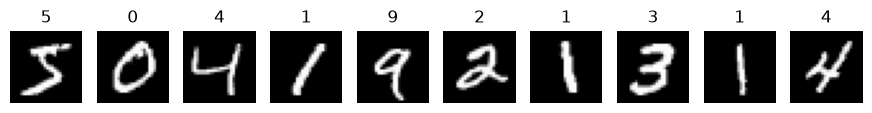

In [2]:
to_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='data', train=True, download=True, transform=to_tensor)
loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2, drop_last=True)

examples = torch.stack([train_set[i][0] for i in range(10)])
show_labels = [train_set[i][1] for i in range(10)]
fig, axes = plt.subplots(1, 10, figsize=(11, 1.6))
for ax, img, lab in zip(axes, examples, show_labels):
    ax.imshow(img[0], cmap='gray', vmin=-1, vmax=1); ax.set_title(str(lab)); ax.axis('off')
plt.show()

### The network

> **Link with the lecture** , *The predictor needs both context and detail*.

The network is a small **U-Net**. It goes down from 28 × 28 to 14 × 14 and 7 × 7 pixels to see the whole digit, then back up to 28 × 28, with *skip connections* that bring back the fine details.

Compared with Lab 1, the network receives **one more input: the label** of the digit we want. It now has three inputs:

1. the noisy image;
2. the noise level;
3. the label (0 to 9), or a special value meaning **"no label"**.

You do not need to read the code of the next cell in detail.

In [ ]:
NO_LABEL = 10   # label used when we hide the digit from the network


def noise_level_features(step, dim):
    """Describe the noise level to the network with sine and cosine waves (as in the DDPM U-Net)."""
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=step.device) / half)
    angles = step.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)


class Block(nn.Module):
    """Two convolutions. The noise level and the label are added to the features in the middle."""
    def __init__(self, c_in, c_out, info_dim):
        super().__init__()
        self.norm1, self.conv1 = nn.GroupNorm(8, c_in), nn.Conv2d(c_in, c_out, 3, padding=1)
        self.info = nn.Linear(info_dim, c_out)
        self.norm2, self.conv2 = nn.GroupNorm(8, c_out), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, info):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.info(info)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class DigitDenoiser(nn.Module):
    """Small U-Net. Inputs: noisy image, noise level, digit label (or NO_LABEL). Output: guessed noise."""
    def __init__(self, ch=64, info_dim=128):
        super().__init__()
        self.info_dim = info_dim
        self.level_mlp = nn.Sequential(nn.Linear(info_dim, info_dim), nn.SiLU(), nn.Linear(info_dim, info_dim))
        self.label_table = nn.Embedding(11, info_dim)                         # digits 0-9 and NO_LABEL
        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = Block(ch, ch, info_dim)                                  # 28 x 28: fine details
        self.pool1 = nn.Conv2d(ch, ch, 4, stride=2, padding=1)
        self.down2 = Block(ch, 2 * ch, info_dim)                              # 14 x 14: strokes and shapes
        self.pool2 = nn.Conv2d(2 * ch, 2 * ch, 4, stride=2, padding=1)
        self.middle = Block(2 * ch, 2 * ch, info_dim)                         # 7 x 7: the whole digit
        self.up2 = nn.ConvTranspose2d(2 * ch, 2 * ch, 4, stride=2, padding=1)
        self.dec2 = Block(4 * ch, 2 * ch, info_dim)
        self.up1 = nn.ConvTranspose2d(2 * ch, ch, 4, stride=2, padding=1)
        self.dec1 = Block(2 * ch, ch, info_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, x, step, label):
        info = self.level_mlp(noise_level_features(step, self.info_dim)) + self.label_table(label)
        h0 = self.inp(x)
        h1 = self.down1(h0, info)
        h2 = self.down2(self.pool1(h1), info)
        m = self.middle(self.pool2(h2), info)
        u2 = self.dec2(torch.cat([self.up2(m), h2], dim=1), info)            # skip connection (fine shapes)
        u1 = self.dec1(torch.cat([self.up1(u2), h1], dim=1), info)           # skip connection (fine details)
        return self.out(u1)


model = DigitDenoiser().to(device)
print(f'The network has {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million parameters.')

The network has 2.0 million parameters.


### Training

The training recipe is the one from Lab 1 (take a real image, choose a noise level, add known noise, ask the network to guess it), with one addition:

> **Link with the lecture** — slide 40, *Classifier-free guidance asks the model twice*: "Training sometimes removes the condition so both predictions are available."

**10 % of the time, we hide the label** and replace it with "no label". The same network therefore learns two tasks: removing noise **for a given digit**, and removing noise **without knowing which digit it is**. We will need both in Part 3.

In [4]:
def train_one_epoch(model, loader, optimizer, hide_label_probability=0.1):
    """One pass over the 60 000 training images, with the recipe of Lab 1 plus the label."""
    model.train()
    errors = []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        step = torch.randint(0, T, (images.shape[0],), device=device)          # random noise levels
        noise = torch.randn_like(images)                                        # noise that we draw ourselves
        a = alpha_bar[step][:, None, None, None]
        noisy = a.sqrt() * images + (1 - a).sqrt() * noise
        hide = torch.rand(labels.shape, device=device) < hide_label_probability # sometimes hide the label
        labels = torch.where(hide, torch.full_like(labels, NO_LABEL), labels)
        error = ((model(noisy, step, labels) - noise) ** 2).mean()
        optimizer.zero_grad(); error.backward(); optimizer.step()
        errors.append(error.item())
    return float(np.mean(errors))

Now start the training. It takes a few minutes on a Colab GPU; the time of each pass over the data (an *epoch*) is printed. **While it runs, read Parts 2 and 3 below.** Do not close the browser tab during training.

In [6]:
n_epochs = 8
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
start = time.time()
for epoch in range(n_epochs):
    error = train_one_epoch(model, loader, optimizer)
    print(f'epoch {epoch + 1}/{n_epochs} · average error {error:.4f} · {time.time() - start:.0f} s')
print('Training finished.')

KeyboardInterrupt: 

**Question 1.** Compare this training recipe with the one in Lab 1. What is new, and why do we sometimes hide the label?

**Your answer:**

 * Unlike Lab 1, the network now receives the digit’s label as well as the noisy image and learns to generate a chosen digit. Sometimes the label is hidden so it also learns to denoise without class information. This lets us guide generation toward a requested digit by comparing conditioned and unconditioned predictions.

## 2 · Ask for a specific digit


The generation loop is the one of Lab 1 (start from pure noise, then predict, move, lower the noise level, predict again), using 50 steps without fresh noise (the DDIM way). The only difference: at each step the network also receives the label of the digit we asked for.

Here we ask for each digit from 0 to 9, three times, with a guidance strength of 3 (explained in Part 3).

In [7]:
@torch.no_grad()
def generate_digits(model, digits, guidance=3.0, n_steps=50, seed=0, keep_estimates_at=()):
    """Generate one image for each requested digit.
    guidance: 0 = ignore the label, 1 = follow it normally, above 1 = exaggerate it."""
    model.eval()
    digits = torch.as_tensor(digits, device=device).long()
    n = len(digits)
    generator = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 1, 28, 28, generator=generator, device=device)          # pure noise
    steps = torch.linspace(T - 1, 0, n_steps).round().long().to(device)
    estimates = {}
    for i, step in enumerate(steps):
        a_now = alpha_bar[step]
        a_next = alpha_bar[steps[i + 1]] if i + 1 < n_steps else torch.tensor(1.0, device=device)
        s = step.repeat(n)
        guess_with_label = model(x, s, digits)                                  # ask once with the label...
        guess_without = model(x, s, torch.full_like(digits, NO_LABEL))         # ...and once without it
        guess = guess_without + guidance * (guess_with_label - guess_without)  # amplify the difference
        clean_estimate = ((x - (1 - a_now).sqrt() * guess) / a_now.sqrt()).clamp(-1, 1)
        guess = (x - a_now.sqrt() * clean_estimate) / (1 - a_now).sqrt()
        if i in keep_estimates_at:
            estimates[i] = clean_estimate.cpu()
        x = a_next.sqrt() * clean_estimate + (1 - a_next).sqrt() * guess        # move and lower the noise level
    images = x.clamp(-1, 1).cpu()
    return (images, estimates) if keep_estimates_at else images


def show_grid(rows, row_titles, col_titles=None, size=1.0):
    """rows: list of image batches (each batch shown as one row)."""
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols + 1.2, size * n_rows + 0.4), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(batch[c, 0], cmap='gray', vmin=-1, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(row_titles[r], rotation=0, ha='right', va='center', fontsize=10)
            if col_titles and r == 0:
                ax.set_title(col_titles[c], fontsize=9)
    plt.show()

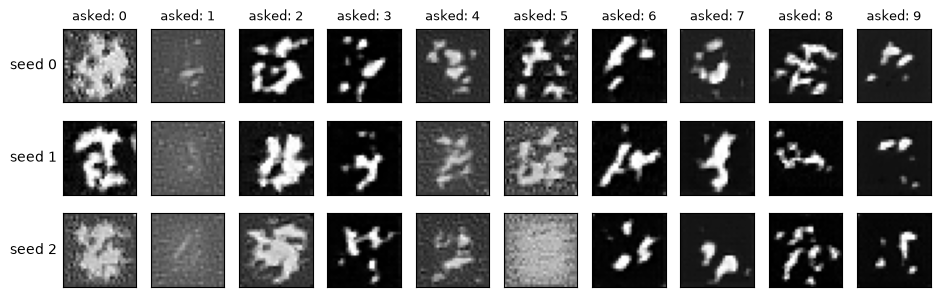

In [8]:
rows = [generate_digits(model, list(range(10)), guidance=3, seed=s) for s in range(3)]
show_grid(rows, ['seed 0', 'seed 1', 'seed 2'], col_titles=[f'asked: {d}' for d in range(10)])

**Question 2.** Did the network draw the digits you asked for? Are the three versions of the same digit identical? What makes them different?

**Your answer:**

* Yes, the network mostly drew the requested digits. The three versions are not identical because each starts from a different random noise pattern, giving the model a different path to follow.

## 3 · Guidance strength

 *Classifier-free guidance: the equation*.

At each step, `generate_digits` asks the network **twice**: once **with** the label and once **without** it. The difference between the two answers is *what the label changes*. The **guidance strength** multiplies this difference:

| Guidance | Meaning |
|---|---|
| 0 | ignore the label (only the answer without label is used) |
| 1 | follow the label normally |
| above 1 | exaggerate what the label changes |

**Predict.** We ask for every digit with guidance 0, 1, 3 and 7, always from the same starting noise. What do you expect in each row?

**Your answer:**

* With the same starting noise, I’d expect guidance 0 to mostly ignore the requested digits, 1 to generate them normally, and 3 to make them clearer. At 7, the digits may follow the labels very strongly but look less natural or have more distortions.

In [ ]:
guidances = [0, 1, 3, 7]
rows = [generate_digits(model, list(range(10)), guidance=g, seed=4) for g in guidances]
show_grid(rows, [f'guidance {g}' for g in guidances], col_titles=[f'asked: {d}' for d in range(10)])

**Question 3.** Describe each row. With guidance 0, are the digits the ones you asked for? What changes between guidance 1, 3 and 7?

**Your answer:**

* With guidance 0, the network ignores the labels, so the digits are not reliably the ones requested. At 1, they generally match the requested digits. At 3, the labels influence the results more strongly, making the digits clearer. At 7, the guidance is very strong, but the digits may look more exaggerated or distorted.


## 4 · Fidelity and variety


We now ask for the digit 7 ten times (ten different seeds), first with guidance 1, then with guidance 7.

**Predict.** Which row will contain the most varied 7s?

**Your answer:**

* I’d expect the row with guidance 1 to contain the most varied 7s. With guidance 7, the stronger guidance may make the results more consistent, but potentially more exaggerated or distorted.

In [ ]:
rows = []
for g in [1, 7]:
    rows.append(torch.cat([generate_digits(model, [7], guidance=g, seed=s) for s in range(10)]))
show_grid(rows, ['guidance 1', 'guidance 7'], col_titles=[f'seed {s}' for s in range(10)])

**Question 4.** Compare the two rows: which one has more variety (thickness, slant, shape)? Which one looks most like a "typical" 7? What is the trade-off when we choose the guidance strength?

**Your answer:**

* The guidance 1 row has more variety in thickness, slant, and shape. The guidance 7 row looks more consistently like a typical 7. The trade-off is that stronger guidance improves how closely outputs follow the requested label, but reduces variety and can make digits look exaggerated.

## 5 · Watch what appears first

At every step, the network's guess gives an **estimate of the final clean image**. Below, we show this estimate at a few steps of the generation, for five digits. The generation has 50 steps; we start the display at step 10, because during the very first steps the estimate is still almost pure noise.

**Predict.** What will appear first: the overall shape of the digit or its fine details?

**Your answer:**

* The overall shape of the digit will appear first. The finer details should emerge later as the noise is gradually removed.

In [ ]:
keep = (9, 14, 19, 24, 34, 49)
final, estimates = generate_digits(model, [0, 2, 3, 5, 8], guidance=3, seed=11, keep_estimates_at=keep)
rows = [torch.stack([estimates[k][i] for k in keep]) for i in range(5)]
show_grid(rows, [f'asked: {d}' for d in [0, 2, 3, 5, 8]], col_titles=[f'step {k + 1}' for k in keep])

**Question 5.** What appears first, and what appears last? Compare with the figure of slide 29 (Ho et al., 2020).

**Your answer:**

* First, the general shape of each digit appears; the image is still blurry and noisy. Last, the fine details and sharper edges emerge. This matches the slide 29 figure: diffusion generation gradually turns noise into a clear image, from coarse structure to finer details.

## 6 · Same starting noise, different digits

We now keep **the same starting noise** and only change the label. Each row uses one starting noise; each column asks for a different digit.

In [ ]:
rows = []
for s in [21, 22, 23]:
    rows.append(torch.cat([generate_digits(model, [d], guidance=3, seed=s) for d in range(10)]))
show_grid(rows, ['noise A', 'noise B', 'noise C'], col_titles=[f'asked: {d}' for d in range(10)])

**Question 6.** Within one row, the starting noise is the same. Do the digits of a row have something in common (thickness, slant, position)? Explain with the lecture: what does the label change, and what does the starting noise decide?

**Your answer:**

* Yes. Digits in the same row share some style features, such as slant, thickness, or position. The label determines which digit is generated, while the starting noise influences its individual style and appearance.
